# GSE193531 — Step 3: Cell-Type Annotation

Scores every cell against 8 canonical marker sets, aggregates scores to the
Leiden-cluster level, assigns each cluster to its highest-scoring cell type
(flagging ambiguous clusters), cross-checks that call against each cluster's
own unbiased marker genes (overriding only where the raw-score call is
directly contradicted), and maps the result back onto every cell.

This cohort (GSE193531) is CD138-sorted plasma cells, so `CD4_T`/`CD8_T`/
`NK_cell` fractions are expected to come out at or near zero for nearly every
cluster — the same 8-marker-set template is applied across every cohort in
this project for schema consistency, so that is the correct, informative
result, not a bug.

**Input:** `data/processed/GSE193531/GSE193531_normalized.h5ad` (from notebook 02)

**Output:**
- `data/processed/GSE193531/GSE193531_annotated.h5ad`
- `results/GSE193531/cell_annotation/GSE193531_cluster_annotation_summary.csv`

This step is fully mechanical — no run-specific hardcoded constants.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

sc.settings.verbosity = 1

#### Directory layout and required files

In [2]:
PROJECT = Path("../")
COHORT = "GSE193531"

PROCESSED_DIR = PROJECT / "data" / "processed" / COHORT
RESULTS_DIR = PROJECT / "results" / COHORT

(RESULTS_DIR / "cell_annotation").mkdir(parents=True, exist_ok=True)

INPUT_H5AD = PROCESSED_DIR / f"{COHORT}_normalized.h5ad"
if not INPUT_H5AD.exists():
    raise FileNotFoundError(INPUT_H5AD)

OUTPUT_H5AD = PROCESSED_DIR / f"{COHORT}_annotated.h5ad"

## Load Normalized AnnData

In [3]:
adata = sc.read_h5ad(INPUT_H5AD)
print(adata)
print()
print(adata.obs["cell_type_candidate"].value_counts())

AnnData object with n_obs × n_vars = 26953 × 22273
    obs: 'sample_id', 'patient_id', 'clinical_stage_standard', 'n_genes', 'doublet_score', 'predicted_doublet', 'n_counts', 'pct_mito', 'pct_ribo', 'pct_hb', 'pct_ig', 'complexity', 'leiden', 'cell_type_candidate'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cell_type_candidate_colors', 'clinical_stage_standard_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_id_colors', 'scrublet', 'umap'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

cell_type_candidate
Plasma candidate    26953
Name: count, dtype: int64


## Canonical Marker Gene Sets

The same 8 cell types are used for every cohort in this project, so
patient-level features stay comparable across cohorts even when a cohort's
sort strategy means some types are barely present. Markers are filtered to
genes actually present in this cohort's `var_names`.

In [4]:
marker_sets_raw = {
    "Plasma_cell": ["MZB1", "SDC1", "PRDM1", "XBP1", "JCHAIN", "CD38", "TNFRSF17", "DERL3", "SLAMF7", "FCRL5"],
    "B_cell": ["MS4A1", "CD79A", "CD79B", "CD19", "CD74", "HLA-DRA", "CD37"],
    "CD4_T": ["CD3D", "CD3E", "CD4", "IL7R", "CD40LG"],
    "CD8_T": ["CD3D", "CD3E", "CD8A", "CD8B", "GZMK"],
    "NK_cell": ["GNLY", "NKG7", "KLRD1", "KLRF1", "NCAM1"],
    "Myeloid": ["LYZ", "CD14", "S100A8", "S100A9", "CST3", "FCN1"],
    "pDC": ["IRF8", "TCF4", "IRF7", "PLAC8", "LILRA4"],
    "Erythroid": ["HBA1", "HBA2", "HBB", "GYPA", "ALAS2"],
}

MIN_MARKERS_PER_TYPE = 2

marker_sets = {}
for cell_type, genes in marker_sets_raw.items():
    present = [g for g in genes if g in adata.var_names]
    missing = [g for g in genes if g not in adata.var_names]
    if missing:
        print(f"{cell_type}: missing {missing}")
    if len(present) < MIN_MARKERS_PER_TYPE:
        print(f"{cell_type}: only {len(present)} marker(s) present, skipping this cell type for this cohort")
        continue
    marker_sets[cell_type] = present

print()
print(f"Scoring {len(marker_sets)} / {len(marker_sets_raw)} cell types: {list(marker_sets)}")


Scoring 8 / 8 cell types: ['Plasma_cell', 'B_cell', 'CD4_T', 'CD8_T', 'NK_cell', 'Myeloid', 'pDC', 'Erythroid']


## Score Cells Against Each Marker Set

`sc.tl.score_genes` scores each cell as the average expression of the marker
set minus the average expression of a random control gene set matched for
expression level.

In [5]:
score_cols = []
for cell_type, genes in marker_sets.items():
    score_name = f"{cell_type}_score"
    sc.tl.score_genes(adata, genes, score_name=score_name, random_state=0)
    score_cols.append(score_name)

adata.obs[score_cols].describe()

,Plasma_cell_score,B_cell_score,CD4_T_score,CD8_T_score,NK_cell_score,Myeloid_score,pDC_score,Erythroid_score
count,26953.000000,26953.000000,26953.000000,26953.000000,26953.000000,26953.000000,26953.000000,26953.000000
mean,0.407688,0.043747,-0.000221,-0.000193,-0.004465,-0.044944,-0.121379,-0.132229
std,0.406239,0.286009,0.021781,0.026550,0.060556,0.198533,0.182350,0.202563
min,-1.284649,-0.625782,-0.037617,-0.034852,-0.112329,-0.388454,-0.531161,-0.476200
25%,0.111612,-0.139587,-0.004648,-0.004689,-0.030806,-0.203925,-0.258908,-0.259437
50%,0.430880,0.004784,-0.001550,-0.001654,-0.019746,-0.098548,-0.146826,-0.202469
75%,0.698351,0.175147,0.000000,0.000000,-0.009011,0.084865,-0.027047,-0.038715
max,2.143830,2.554817,0.498011,0.804392,1.150490,1.311846,1.495457,1.166477


## Assign Cell Type per Leiden Cluster

Scores are aggregated to the cluster level (mean per cluster) rather than
per cell. Each cluster is assigned to its highest-scoring cell type, unless
the top two scores are within `MIN_MARGIN` of each other, or the top score
itself is at or below 0 — both are labeled `Ambiguous`.

In [6]:
MIN_MARGIN = 0.05

cluster_scores = adata.obs.groupby("leiden", observed=True)[score_cols].mean()
cluster_scores.columns = [c.replace("_score", "") for c in cluster_scores.columns]

top1_type = cluster_scores.idxmax(axis=1)
top1_score = cluster_scores.max(axis=1)
top2_score = cluster_scores.apply(lambda row: row.sort_values(ascending=False).iloc[1], axis=1)
margin = top1_score - top2_score

is_ambiguous = (margin < MIN_MARGIN) | (top1_score <= 0)

cluster_annotation = pd.DataFrame({
    "leiden": cluster_scores.index,
    "n_cells": adata.obs["leiden"].value_counts().reindex(cluster_scores.index),
    "assigned_type": np.where(is_ambiguous, "Ambiguous", top1_type),
    "top_type": top1_type,
    "top_score": top1_score.round(3),
    "second_score": top2_score.round(3),
    "margin": margin.round(3),
}).reset_index(drop=True)

cluster_annotation

,leiden,n_cells,assigned_type,top_type,top_score,second_score,margin
0,0,5062,Plasma_cell,Plasma_cell,0.574,0.119,0.455
1,1,3191,Ambiguous,NK_cell,0.029,0.005,0.023
2,2,2667,Plasma_cell,Plasma_cell,0.483,0.396,0.087
3,3,1947,Plasma_cell,Plasma_cell,0.446,0.198,0.248
4,4,1684,Plasma_cell,Plasma_cell,0.614,0.354,0.260
5,5,1574,Ambiguous,B_cell,0.012,-0.002,0.014
6,6,1356,Ambiguous,NK_cell,0.019,-0.001,0.021
7,7,1111,Plasma_cell,Plasma_cell,0.876,-0.001,0.877
8,8,1074,Plasma_cell,Plasma_cell,0.952,-0.002,0.954
9,9,960,pDC,pDC,0.084,0.033,0.051


## Cross-Check Cluster Scores Against Unbiased Marker Genes

Averaging continuous `score_genes` values across marker sets of different
sizes is not perfectly scale-comparable: a broad, non-specific marker set can
outscore a small but highly specific one even in a cluster the specific set
actually defines. For each cluster, this counts how many of each marker
set's genes appear in that cluster's own top-15 unbiased DE genes, and
overrides the raw-score assignment only when it is directly contradicted —
the assigned type has **zero** DE-gene hits while some other single type has
at least `MIN_DE_OVERLAP` hits.

In [7]:
MIN_DE_OVERLAP = 2
TOP_N_DE_GENES = 15

top_de_genes = pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(TOP_N_DE_GENES)
top_de_genes.columns = top_de_genes.columns.astype(str)

de_overlap_counts = pd.DataFrame(
    {
        cell_type: [len(set(top_de_genes[cl]) & set(genes)) for cl in cluster_annotation["leiden"]]
        for cell_type, genes in marker_sets.items()
    },
    index=cluster_annotation["leiden"],
)

overrides = []
final_assigned = cluster_annotation.set_index("leiden")["assigned_type"].copy()

for cl, current in final_assigned.items():
    counts = de_overlap_counts.loc[cl]
    current_hits = counts.get(current, 0) if current != "Ambiguous" else 0

    if current_hits > 0:
        continue  # raw-score call already has direct DE support; leave it

    contradicting = counts[counts >= MIN_DE_OVERLAP]
    if len(contradicting) == 1:
        new_type = contradicting.index[0]
        overrides.append({
            "leiden": cl, "from": current, "to": new_type,
            "de_hits": ", ".join(sorted(set(top_de_genes[cl]) & set(marker_sets[new_type]))),
        })
        final_assigned[cl] = new_type

cluster_annotation["assigned_type"] = cluster_annotation["leiden"].map(final_assigned)

print(f"{len(overrides)} cluster(s) overridden by unbiased DE evidence:")
pd.DataFrame(overrides)

1 cluster(s) overridden by unbiased DE evidence:


,leiden,from,to,de_hits
0,4,Plasma_cell,Myeloid,"LYZ, S100A8, S100A9"


## Cross-Check Against the Manual `cell_type_candidate` Calls

Agreement is a sanity check on the systematic method; disagreement is not
automatically a problem, but should be inspected before trusting either
label.

In [8]:
cluster_to_type = cluster_annotation.set_index("leiden")["assigned_type"]
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_type).astype("category")

pd.crosstab(adata.obs["cell_type"], adata.obs["cell_type_candidate"])

cell_type_candidate,Plasma candidate
cell_type,
Ambiguous,6148
B_cell,163
Erythroid,498
Myeloid,1684
Plasma_cell,17500
pDC,960


## Visualize

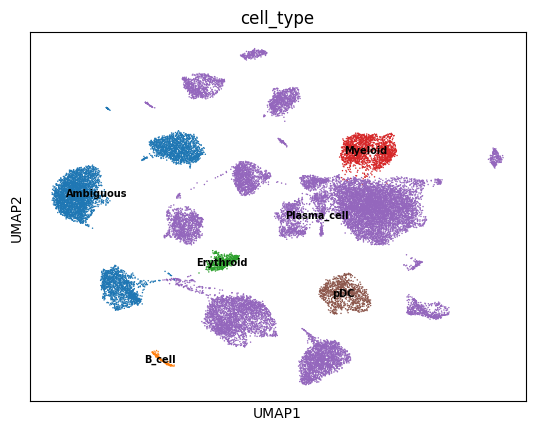

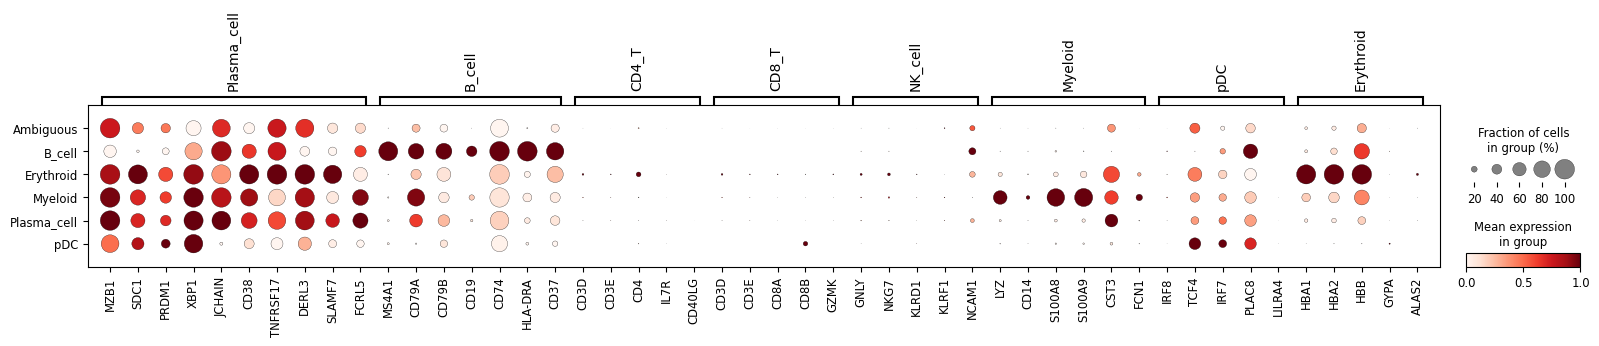

In [9]:
sc.pl.umap(adata, color="cell_type", legend_loc="on data", legend_fontsize=7)
sc.pl.dotplot(adata, marker_sets, groupby="cell_type", standard_scale="var")

## Save Annotated AnnData

In [10]:
adata.write(OUTPUT_H5AD)

summary_path = RESULTS_DIR / "cell_annotation" / f"{COHORT}_cluster_annotation_summary.csv"
cluster_annotation.to_csv(summary_path, index=False)

print(f"Saved annotated AnnData: {OUTPUT_H5AD}")
print(f"Saved cluster annotation summary -> {summary_path}")
print()
print("Cell type counts:")
print(adata.obs["cell_type"].value_counts())

Saved annotated AnnData: ../data/processed/GSE193531/GSE193531_annotated.h5ad
Saved cluster annotation summary -> ../results/GSE193531/cell_annotation/GSE193531_cluster_annotation_summary.csv

Cell type counts:
cell_type
Plasma_cell    17500
Ambiguous       6148
Myeloid         1684
pDC              960
Erythroid        498
B_cell           163
Name: count, dtype: int64
